# Desenvolvimento do modelo de Regressão Logística
---

A `Regressão Logística` é um algoritmo fundamental de aprendizado supervisionado utilizado para problemas de classificação, apesar de carregar "regressão" no nome.

Diferente da Regressão Linear, que prevê números contínuos, a Regressão Logística prevê a probabilidade de uma amostra pertencer a uma classe específica (geralmente binária, como `Sim` e `Não` ou `0` e `1`).

Utiliza de:

- O algoritmo utiliza a `Função Logística` (ou `Sigmóide`) para "achatar" qualquer valor numérico em um intervalo entre 0 e 1.
- Define-se um limiar (geralmente 0,5). Se a probabilidade calculada for maior que 0,5, o modelo classifica como classe A; se for menor, como classe B.

Uso em `Machine Learning`:

- `Classificação Binária`: É o uso mais comum. Exemplos incluem detecção de spam, diagnóstico médico, aprovação de crédito e no caso deste projeto, determinar a probabilidade de ser um ataque cibernético.

- `Base para Modelos Complexos`: É frequentemente usada como um baseline (modelo de referência inicial) devido à sua simplicidade e rapidez.

- `Interpretabilidade`: Em Machine Learing, é muito valorizada porque permite entender o peso de cada variável na decisão final (quão importante cada característica é para a probabilidade).


Principais fórmulas estatísticas:

1. `Equação Linear (Logit)`:

   Antes de chegar à probabilidade, o modelo calcula um valor intermediário ($z$), que é uma combinação linear dos atributos (features) do seu conjunto de dados:

   <div style="text-align: center;">
      <img src="../../imagens/logit.png" width="480">
   </div>


2. `Função Sigmóide (Função Logística)`:
  
   Para converter esse valor `z` (que pode ir de `-infinito` a `+infinto`) em uma probabilidade `P` entre 0 e 1, utiliza-se a `função sigmóide`:

    <div style="text-align: center;">
      <img src="../../imagens/funcao_sigmoide.png" width="480">
    </div>

3. `Função de Custo (Log Loss / Entropia Cruzada)`:

Não se usa o `Erro Quadrático Médio` (como na regressão linear) porque a `sigmóide` tornaria a função não-convexa. Usa-ses `Log Loss`:

<div style="text-align: center;">
  <img src="../../imagens/log_loss.png" width="480">
</div>

4. `Razão de Chances (Odds Ratio)`:

    A `Regressão Logística` também pode ser expressa em termos de `odds (chances)`, que é a razão entre a probabilidade de sucesso e a de fracasso:

<div style="text-align: center;">
  <img src="../../imagens/odds_ratio.png" width="480">
</div>

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados:
---

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
from sklearn.preprocessing import PolynomialFeatures, RobustScaler
from imblearn.over_sampling import SMOTE

### 2. Pacote Predexan:
---

In [11]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\vitor\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [12]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   protocolo_rede                      96822 non-null  float64
 2   servico_conexao                     96822 non-null  float64
 3   estado_conexao                      96822 non-null  float64
 4   num_pacotes_origem                  96822 non-null  float64
 5   num_pacotes_destino                 96822 non-null  float64
 6   total_bytes_origem                  96822 non-null  float64
 7   total_bytes_destino                 96822 non-null  float64
 8   taxa_pacote                         96822 non-null  float64
 9   carga_origem                        96822 non-null  float64
 10  carga_destino                       96822 non-null  float64
 11  pacotes_perdidos_origem             96822 non-null  floa

### 2. Deteminando df_teste
---

In [13]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   protocolo_rede                      49971 non-null  float64
 2   servico_conexao                     49971 non-null  float64
 3   estado_conexao                      49971 non-null  float64
 4   num_pacotes_origem                  49971 non-null  float64
 5   num_pacotes_destino                 49971 non-null  float64
 6   total_bytes_origem                  49971 non-null  float64
 7   total_bytes_destino                 49971 non-null  float64
 8   taxa_pacote                         49971 non-null  float64
 9   carga_origem                        49971 non-null  float64
 10  carga_destino                       49971 non-null  float64
 11  pacotes_perdidos_origem             49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

A escolha de target **provisória** é `label` por conta da razão utilidade/custo computacional, mas ainda será ***conversado com o professor*** a possibilidade de se voltar a usar `categoria_ataque`, mesmo que este não tenha sido processado de forma eficiente pelas máquinas a disposição, em primeiro momento. 

### 1. Atributos do df_treino
---

In [14]:
# Features
X_treino = df_treino.drop(columns='label')
# X_treino = df_treino.drop(columns='categoria_ataque')

# Target
y_treino = df_treino['label']
# y_treino = df_treino['categoria_ataque']

### 2. Atributos do df_teste
---

In [15]:
# Features
X_teste = df_teste.drop(columns='label')
# X_teste = df_teste.drop(columns='categoria_ataque')

# Target
y_teste = df_teste['label']
# y_teste = df_teste['categoria_ataque']

## D) Visualização dos dados
---

Serão visualizados com `Regressão Logística`, apenas as features não categóricas do dataset de treino.

### 1. Feature duracao_conexao_seg
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0992 segundos


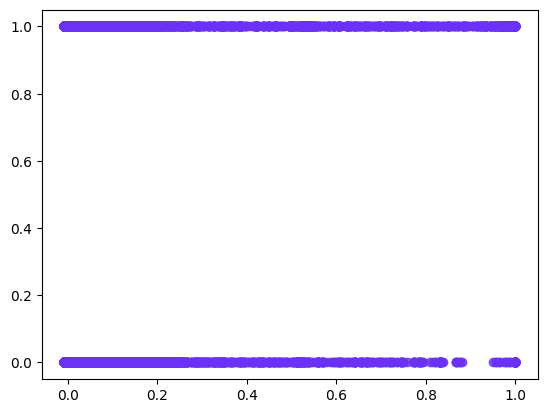

In [16]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'duracao_conexao_seg', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Quanto maior a duração da conexão, maior a probabilidade de haver ataque cibernético (label=1). Por outro lado, quanto menor a duração, menor a probabilidade de haver ataque (label=0).

### 2. Feature num_pacotes_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0498 segundos


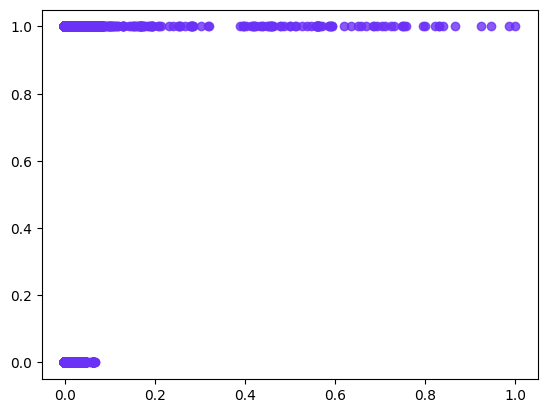

In [17]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_pacotes_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Conexões classificadas como ataque (label=1) predominam amplamente em toda a faixa de valores de num_pacotes_origem, enquanto conexões normais (label=0) concentram-se em valores muito baixos. Isso indica que um número elevado de pacotes originados é um forte indicativo de tráfego malicioso.

### 3. Feature num_pacotes_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0424 segundos


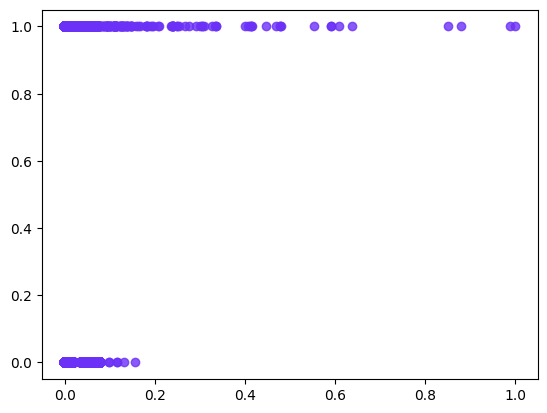

In [18]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_pacotes_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

O padrão observado em num_pacotes_destino é semelhante ao de num_pacotes_origem: conexões de ataque (label=1) distribuem-se por toda a faixa de valores, enquanto conexões normais (label=0) concentram-se em valores baixos. Isso reforça que fluxos com alto volume de pacotes — tanto na origem quanto no destino — estão fortemente associados a comportamento malicioso

### 4. Feature total_bytes_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0360 segundos


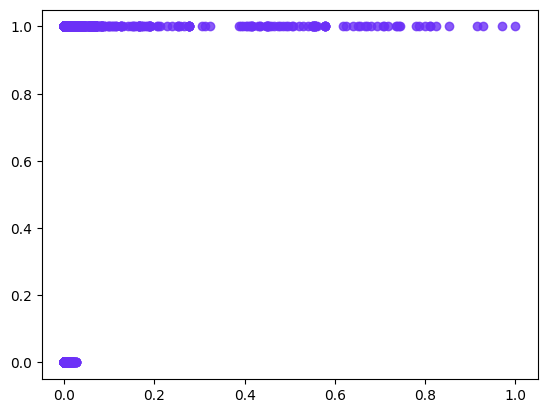

In [19]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'total_bytes_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Em total_bytes_origem, a separação entre classes é ainda mais pronunciada que nas features anteriores: conexões normais (label=0) são raríssimas e restritas a volumes de bytes muito baixos, enquanto ataques (label=1) dominam amplamente toda a faixa. Isso sugere que um alto volume de bytes transmitidos pela origem é um indicador muito forte de tráfego malicioso.

### 5. Feature total_bytes_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0338 segundos


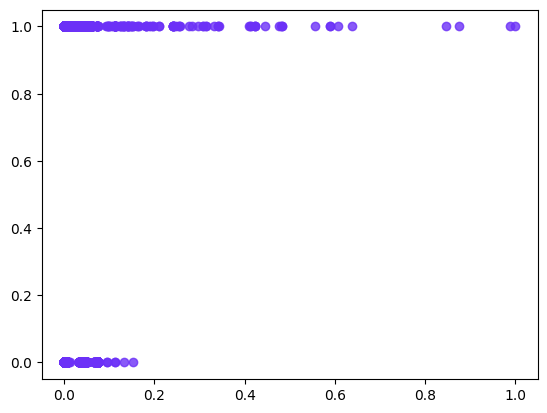

In [20]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'total_bytes_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

O comportamento de total_bytes_destino espelha o de total_bytes_origem: ataques (label=1) ocorrem em toda a faixa de volume de bytes recebidos pelo destino, enquanto conexões normais (label=0) praticamente inexistem ou ficam restritas a valores muito baixos. O alto volume de bytes no destino reforça a caracterização de tráfego malicioso.

### 6. Feature taxa_pacote
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0357 segundos


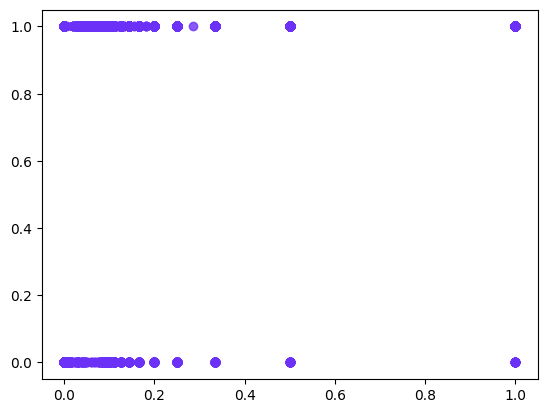

In [21]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'taxa_pacote', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

A taxa_pacote mede a razão entre o número de pacotes e a duração da conexão. Conexões de ataque (label=1) apresentam uma ampla variação nessa taxa, enquanto conexões normais (label=0) tendem a concentrar-se em taxas baixas. Uma taxa de pacotes elevada pode indicar varreduras de rede, flooding ou outras formas de ataque que geram tráfego intenso em curto intervalo de tempo.

### 7. Feature carga_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0365 segundos


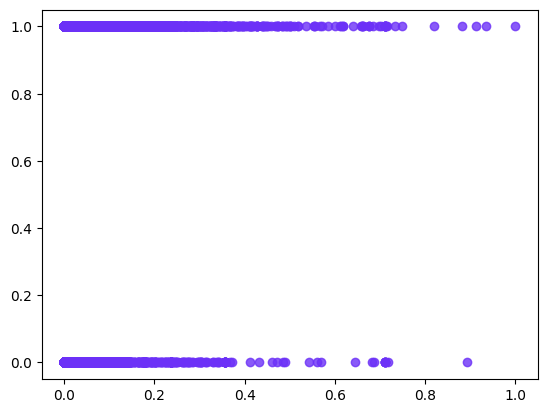

In [22]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'carga_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

carga_origem representa o volume médio de dados úteis (payload) enviados pela origem por unidade de tempo. Ataques (label=1) distribuem-se por toda a faixa de valores, ao passo que conexões normais (label=0) concentram-se em cargas baixas. Uma carga elevada originada pode indicar exfiltração de dados ou ataques de injeção com grandes payloads.

### 8. Feature carga_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0421 segundos


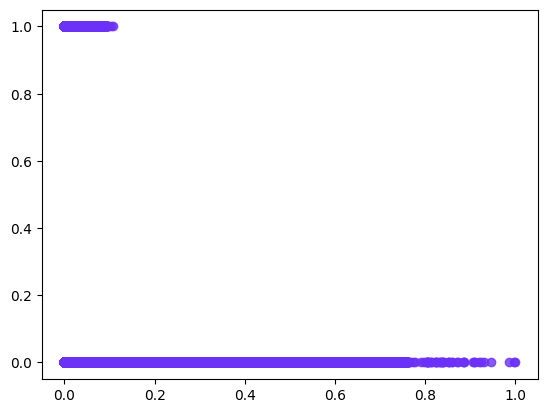

In [23]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'carga_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

De forma análoga à carga_origem, a carga_destino mensura o volume médio de payload recebido pelo destino. O padrão se repete: ataques (label=1) dominam toda a faixa, enquanto tráfego normal (label=0) fica restrito a valores baixos. Isso sugere que grandes volumes de dados recebidos também são um indicador relevante de comportamento malicioso.

### 9. Feature pacotes_perdidos_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0526 segundos


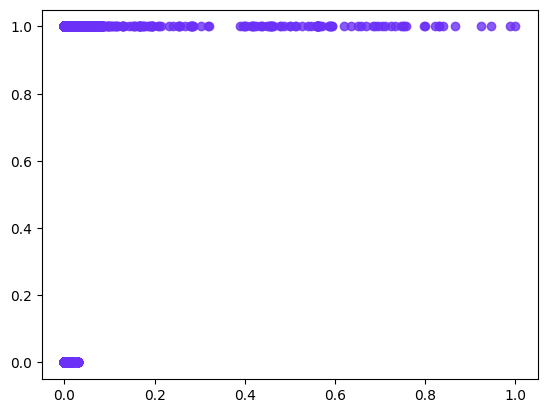

In [24]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'pacotes_perdidos_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

pacotes_perdidos_origem indica a quantidade de pacotes descartados ou não entregues pelo lado da origem. Ataques (label=1) tendem a apresentar maior perda de pacotes, reflexo de técnicas como flooding que saturam a rede. Conexões normais (label=0) geralmente apresentam perda mínima ou nula.

### 10. Feature pacotes_perdidos_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0367 segundos


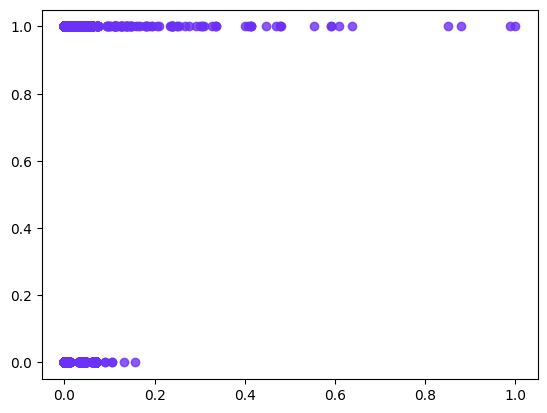

In [25]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'pacotes_perdidos_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Similar à feature anterior, pacotes_perdidos_destino mede a perda no lado do destino. O mesmo padrão se mantém: ataques (label=1) concentram valores mais altos de perda, enquanto conexões legítimas (label=0) apresentam perda próxima de zero. A perda de pacotes no destino pode indicar sobrecarga intencional provocada pelo atacante.

### 11. Feature tempo_medio_pacote_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0341 segundos


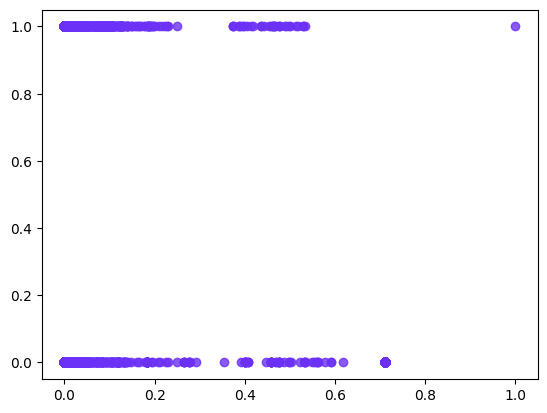

In [26]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tempo_medio_pacote_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

tempo_medio_pacote_origem representa o intervalo médio de tempo entre pacotes enviados pela origem. Ataques (label=1) ocorrem em toda a faixa de valores, mas conexões normais (label=0) tendem a apresentar intervalos maiores — tráfego malicioso muitas vezes envia pacotes em rajadas com intervalos muito curtos entre eles.

### 12. Feature bytes_por_pacote_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0327 segundos


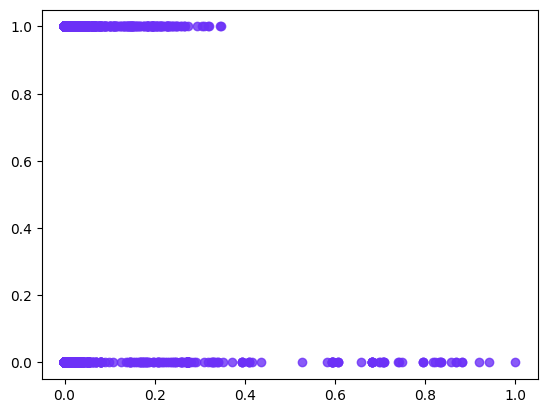

In [27]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'bytes_por_pacote_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Esta feature mede a quantidade média de bytes por pacote recebido no destino. Ataques (label=1) distribuem-se por toda a faixa, ao passo que conexões normais (label=0) concentram-se em valores baixos. Pacotes muito grandes recebidos pelo destino podem indicar tentativas de buffer overflow ou transferências não autorizadas de dados.

### 13. Feature var_lat_pacotes_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0331 segundos


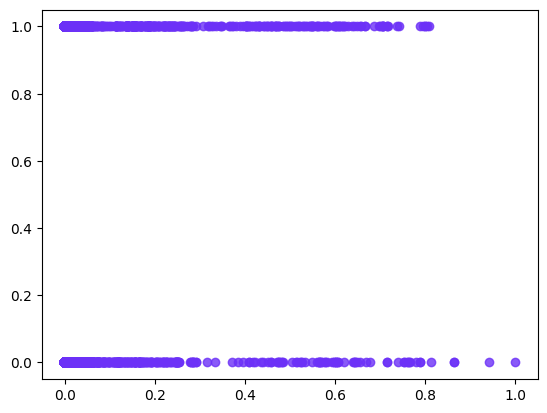

In [28]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'var_lat_pacotes_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

var_lat_pacotes_origem captura a variância da latência entre pacotes enviados pela origem. Alta variância é associada a ataques (label=1), pois ferramentas maliciosas frequentemente geram tráfego irregular. Conexões normais (label=0) tendem a ter latência mais estável, concentrando-se em valores baixos dessa métrica.

### 14. Feature var_lat_pacotes_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0346 segundos


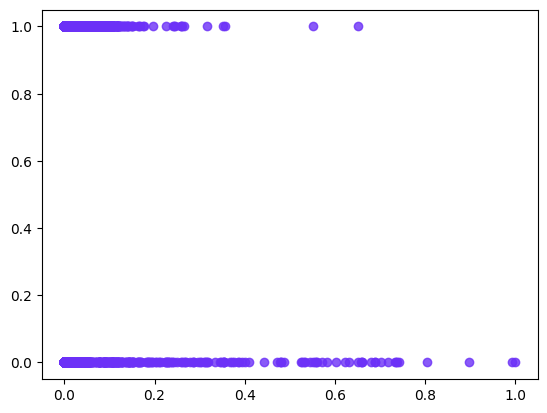

In [29]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'var_lat_pacotes_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Analogamente à feature anterior, var_lat_pacotes_destino mede a variância da latência no lado do destino. O mesmo comportamento se observa: maior variância está associada a ataques (label=1), enquanto tráfego legítimo (label=0) apresenta variância reduzida e mais previsível.

### 15. Feature tamanho_janela_tcp_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0366 segundos


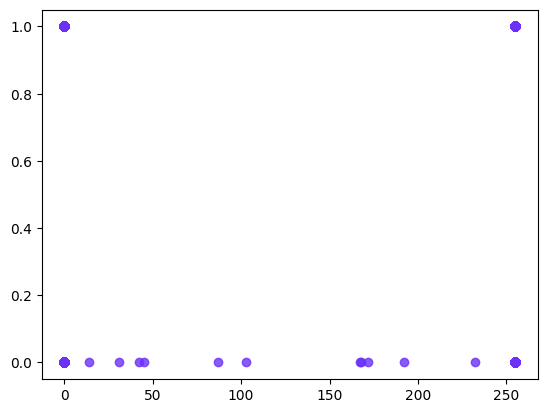

In [30]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tamanho_janela_tcp_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

O tamanho da janela TCP da origem controla a quantidade de dados que podem ser enviados sem confirmação. Ataques (label=1) exploram janelas TCP de diferentes tamanhos, enquanto conexões normais (label=0) tendem a concentrar-se em valores padrão mais baixos. Manipulação do tamanho da janela é uma técnica comum em ataques de negação de serviço e varreduras.

### 16. Feature num_sequencia_tcp_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0288 segundos


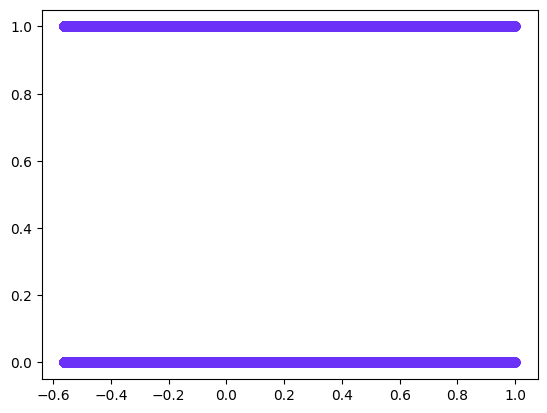

In [31]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_sequencia_tcp_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

O número de sequência TCP da origem identifica a ordem dos pacotes na conexão. Ataques (label=1) distribuem-se amplamente nessa faixa, pois ferramentas de ataque frequentemente manipulam ou randomizam números de sequência. Conexões normais (label=0) tendem a concentrar-se em faixas mais específicas e previsíveis.

### 17. Feature num_sequencia_tcp_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0354 segundos


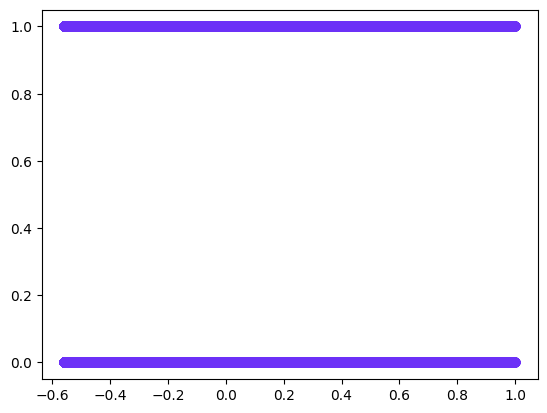

In [32]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_sequencia_tcp_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Espelhando o comportamento da feature anterior, num_sequencia_tcp_destino apresenta ataques (label=1) distribuídos por toda a faixa de valores. A manipulação de números de sequência TCP no destino é indicativa de técnicas como session hijacking e spoofing, confirmando sua relevância para a detecção de ataques.

### 18. Feature tamanho_janela_tcp_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0350 segundos


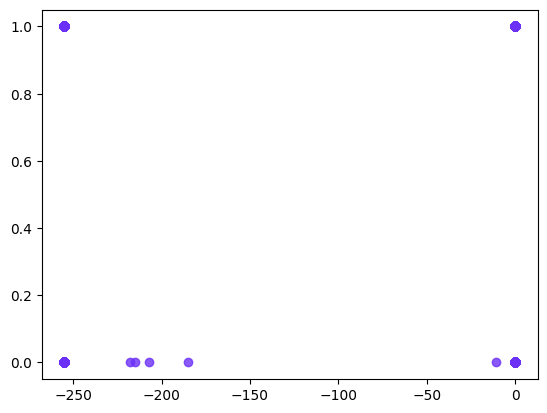

In [33]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tamanho_janela_tcp_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Similar ao tamanho_janela_tcp_origem, esta feature apresenta ataques (label=1) em toda a faixa de tamanhos de janela TCP no destino. Conexões normais (label=0) concentram-se em valores típicos de janela. A variação no tamanho da janela do destino pode indicar respostas a tentativas de flooding ou SYN flood.

### 19. Feature rtt_handshake_tcp
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0332 segundos


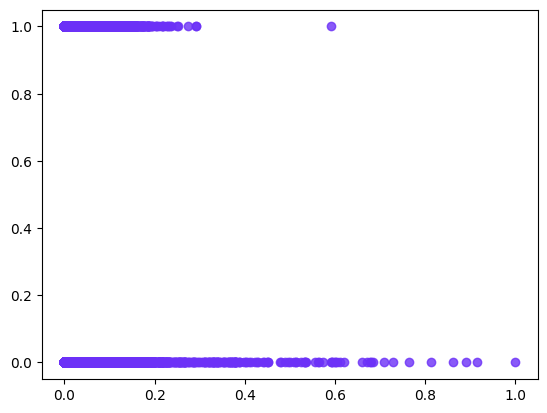

In [34]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'rtt_handshake_tcp', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

O RTT (Round-Trip Time) do handshake TCP mede o tempo total do processo de estabelecimento da conexão. Ataques (label=1) tendem a apresentar RTTs variados — ataques remotos ou com spoofing podem gerar latências atípicas. Conexões normais (label=0) geralmente concentram-se em valores de RTT mais baixos e consistentes.

### 20. Feature tempo_syn_synack
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0348 segundos


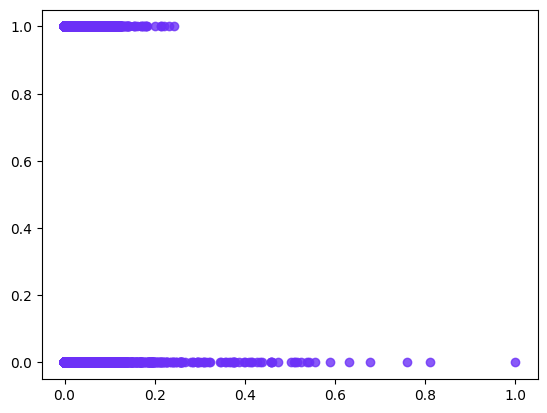

In [35]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tempo_syn_synack', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

tempo_syn_synack mede o intervalo entre o pacote SYN enviado pelo cliente e o SYN-ACK respondido pelo servidor. Ataques como SYN flood (label=1) tendem a apresentar valores elevados ou anômalos nessa métrica, pois o servidor pode demorar a responder sob sobrecarga. Conexões normais (label=0) concentram-se em tempos baixos.

### 21. Feature tempo_synack_ack
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0397 segundos


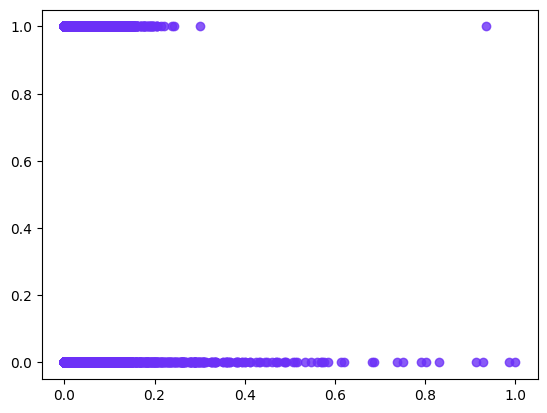

In [36]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tempo_synack_ack', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Esta feature mede o intervalo entre o SYN-ACK do servidor e o ACK final do cliente, completando o three-way handshake. Em ataques (label=1), esse tempo pode ser anômalo — em SYN floods, o ACK final nunca chega, e em outros ataques, pode ser manipulado. Conexões legítimas (label=0) completam esse processo rapidamente.

### 22. Feature tamanho_medio_pacotes_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0385 segundos


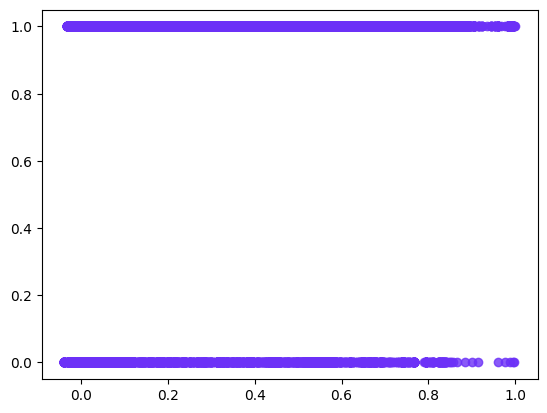

In [37]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tamanho_medio_pacotes_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

tamanho_medio_pacotes_origem representa o tamanho médio dos pacotes enviados pela origem. Ataques (label=1) abrangem toda a faixa de tamanhos, enquanto conexões normais (label=0) tendem a concentrar-se em tamanhos específicos e previsíveis. Pacotes muito pequenos em alta frequência podem indicar ataques de flooding; pacotes muito grandes podem indicar tentativas de overflow.

### 23. Feature tamanho_medio_pacotes_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0334 segundos


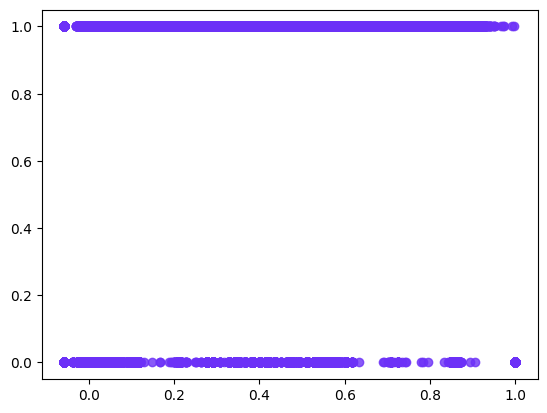

In [38]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tamanho_medio_pacotes_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Analogamente, tamanho_medio_pacotes_destino mede o tamanho médio dos pacotes recebidos. O padrão se repete: ataques (label=1) distribuem-se amplamente, ao passo que tráfego normal (label=0) concentra-se em faixas típicas. A assimetria entre tamanho médio de pacotes de origem e destino pode ser, por si só, um indicador adicional de anomalia.

### 24. Feature profundidade_transacao_http
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0345 segundos


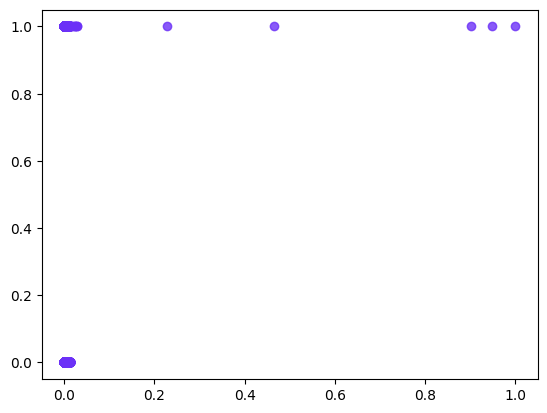

In [39]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'profundidade_transacao_http', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

profundidade_transacao_http mede a profundidade ou complexidade das transações HTTP em uma conexão. Ataques baseados em HTTP (label=1), como injeções ou crawlers maliciosos, tendem a gerar transações mais profundas ou numerosas. Conexões normais (label=0) geralmente apresentam profundidade de transação mais baixa e uniforme.

### 25. Feature tamanho_corpo_resposta_http
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0331 segundos


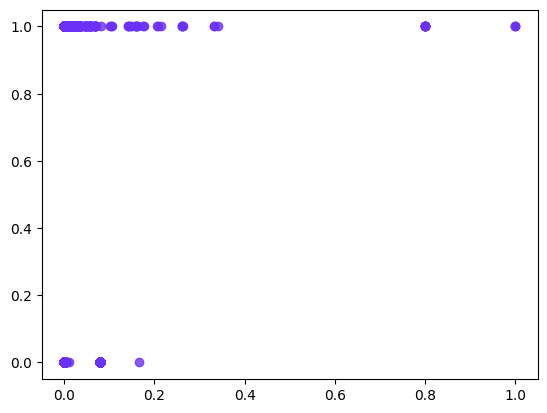

In [40]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'tamanho_corpo_resposta_http', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Esta feature captura o tamanho do corpo das respostas HTTP. Ataques (label=1) podem gerar respostas de tamanhos variados — desde respostas mínimas em ataques de enumeração até respostas muito grandes em exfiltração de dados. Conexões normais (label=0) tendem a apresentar tamanhos de resposta mais consistentes e dentro de padrões esperados

### 26. Feature conexoes_recentes_ip_porta_destino
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0544 segundos


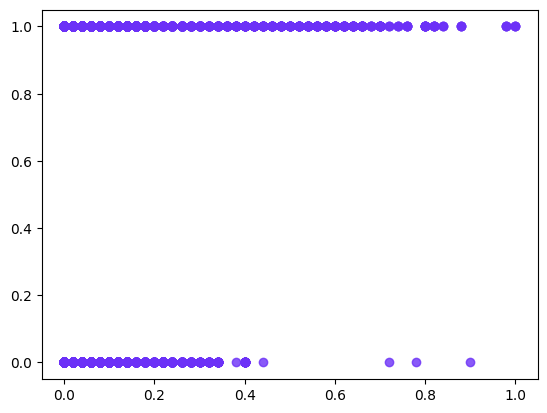

In [41]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'conexoes_recentes_ip_porta_destino', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Mede quantas conexões recentes foram feitas para o mesmo IP e porta de destino. Um número elevado de conexões recentes para o mesmo destino (label=1) é forte indicativo de varredura de portas, brute force ou DDoS. Conexões normais (label=0) geralmente apresentam poucos acessos recentes ao mesmo destino.

### 27. Feature conexoes_recentes_ip_porta_origem
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0346 segundos


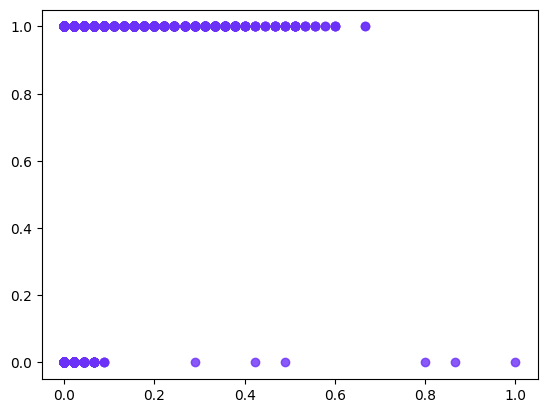

In [42]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'conexoes_recentes_ip_porta_origem', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Análoga à feature anterior, mas pelo lado da origem: mede quantas conexões recentes partiram do mesmo IP e porta de origem. Alta frequência de conexões originadas do mesmo ponto (label=1) é indicativa de ataques automatizados, como bots ou scanners. Tráfego legítimo (label=0) tende a ser mais esparso e menos repetitivo.

### 28. Feature ftp_autenticada
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0372 segundos


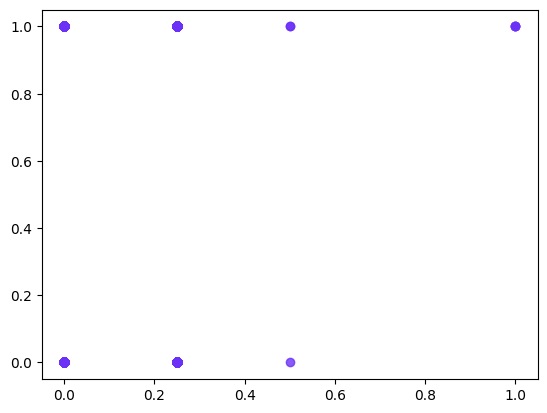

In [43]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'ftp_autenticada', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

ftp_autenticada é uma variável binária que indica se a sessão FTP foi autenticada (1) ou não (0). Conexões FTP não autenticadas são fortemente associadas a ataques (label=1), como tentativas de acesso anônimo não autorizado ou brute force. Sessões autenticadas têm maior probabilidade de ser tráfego legítimo (label=0).

### 29. Feature num_comandos_ftp
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0263 segundos


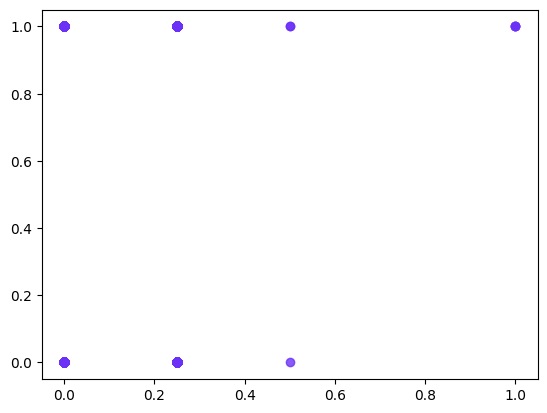

In [44]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_comandos_ftp', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Esta feature conta o número de comandos FTP emitidos em uma sessão. Um número elevado de comandos (label=1) pode indicar automação maliciosa, como scripts de exfiltração ou enumeração de arquivos. Conexões normais (label=0) tendem a emitir poucos comandos FTP por sessão.

### 30. Feature num_metodos_http
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0373 segundos


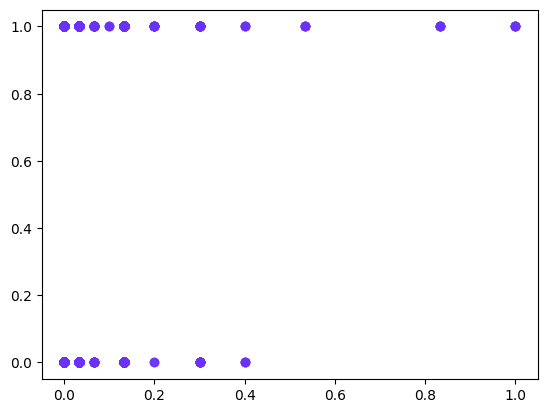

In [45]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'num_metodos_http', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

num_metodos_http mede a variedade de métodos HTTP utilizados em uma conexão (GET, POST, PUT, DELETE, etc.). Ataques (label=1) frequentemente exploram múltiplos métodos HTTP para testar vulnerabilidades ou realizar injeções. Conexões normais (label=0) geralmente utilizam poucos métodos e de forma previsível.

### 31. Feature ip_porta_origem_destino_iguais
---

Ocorreu o seguinte erro: `logistic=True` requires statsmodels, an optional dependency, to be installed.
Tempo total do processo: 0.0385 segundos


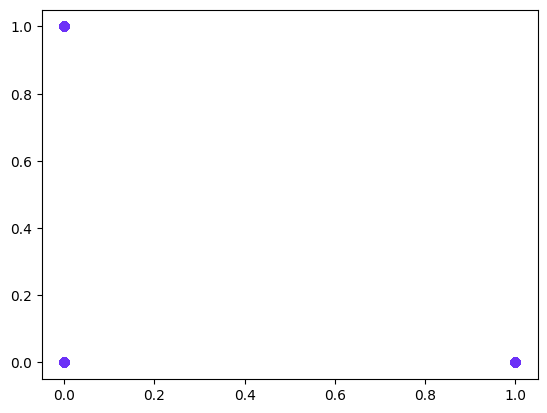

In [46]:
comeco_processo = time.time()
plot = pg.gerar_regplot(df_treino, 'ip_porta_origem_destino_iguais', 'label', log=True)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Esta feature indica se o IP e a porta de origem são iguais aos de destino — uma situação atípica em tráfego legítimo. Quando verdadeiro, está fortemente associado a ataques (label=1), pois pode indicar técnicas de spoofing, loopback malicioso ou reflexão de pacotes usadas em ataques DDoS. Conexões normais (label=0) raramente apresentam essa condição.

## E) Desenvolvimento do Modelo
---

### 1. Aplicação da classe SMOTE para balanceamento de classes nas variáveis de treino
---

- Target **label**:

O uso da classe `SMOTE`se mostra **injustificado** para o target `label` uma vez que ele já está naturalmente balanceado na base de treino.

In [9]:
# df_treino['label'].value_counts()

- Target **categoria_ataque**:

Todavia, para `categoria_ataque`, o uso desta tecnologia de balanceamento de classes é **essencial**, uma vez que já foi mostrado o desbalenceamento tanto com o método `.value_counts()` quanto pela análise do `Scatterplot` e `t-SNE` no notebook de `Pré-Processamento` e `Análise de Dados` de treino, onde a clusterização era intensa em grandes clusters, enquanto alguns tipos de ataques não apareciam, devido a baixa densidade em relação aos demais agrupados.

In [10]:
# df_treino['categoria_ataque'].value_counts()

Observação: a classe `SMOTE` deve ser usada apenas nos dados de treino do modelo, pois aplicá-la ao conjunto de teste mascara o desempenho real ao avaliar o modelo em dados sintéticos e artificiais.

#### 1.1. Instanciamento da classe SMOTE
---

In [11]:
# sm = SMOTE(random_state=42)

#### 1.2. Reamostragem para balanceamento do conjuto de dados
---

In [12]:
# X_treino_balanceado, y_treino_balanceado = sm.fit_resample(X_treino, y_treino)

#### 1.3. Conferência do balanceamento do Target categoria_ataque
---

In [13]:
# print(f'Target CATEGORIA_ATAQUE:\n')
# print(f'- Antes da aplicação do SMOTE:\n \n{y_treino.value_counts()}\n')
# print(f'- Depois da aplicação do SMOTE:\n \n{y_treino_balanceado.value_counts()}\n')

### 2. Aplicação de PolynomialFeatures
---

***Tirar Dúvida com o professor sobre funcionalidade para o projeto e desempenho.***

A aplicação de `PolynomialFeatures` busca gerar interações entre as variáveis, permitindo que o modelo de `Regressão Logística` capture relações não-lineares nos dados. Isso aumenta a complexidade do espaço de atributos, possibilitando o mapeamento de padrões mais sofisticados que impactam o alvo, mas que não são perceptíveis de forma linear isolada.

#### 2.1. Criação da instância da função PolynomialFeatures
---

In [14]:
# poly = PolynomialFeatures()

#### 2.2. Aprendizagem e transformação com as features do Dataset de Treino
---

In [37]:
# X_treino_poly = poly.fit_transform(X_treino_balanceado)
# X_treino_poly

#### 2.3. Transformação com as features do Dataset de Teste
---

O teste só é transformado para que o modelo aprenda apenas os dados de treino e evitar, assim, o `overfitting` que diminuiria o desempenho dele com dados reais.

In [16]:
# X_teste_poly = poly.transform(X_teste)
# X_teste_poly

#### 2.4. Normalização das Features de Treino e Teste
---

Foi visto no array de `X_treino_poly` e `X_teste_poly` que seus valores foram desnormalizados com  a aplicação de PolynomialFeatures, portanto, estes devem ser normalizados. Uma boa oção para esse caso é o `RobustScaler` pois as bases de dados são naturalmente não normais e com grandes quantidade de outliers, além de ele já ter sido usado nos notebooks de pré-processamento de dados destas bases.

In [17]:
# type(X_treino_poly)

In [18]:
# type(X_teste_poly)

É necessário transformar os arrays em df para ter maior controle das features e seus dados.

##### 2.4.1. Instanciamento da classe RobustScaler()
---

In [19]:
# escalonador = RobustScaler()

##### 2.4.2. Normalização de X_treino_poly
---

In [20]:
# # Conversão para df
# X_treino_poly = pd.DataFrame(X_treino_poly, columns=X_treino_balanceado.columns)

# # Lista que contém os atributos categóricos e/ou com poucos valores únicos
# atr_nao_categoricos_treino = X_treino_poly.drop(columns=['protocolo_rede','tamanho_janela_tcp_origem', 'servico_conexao','estado_conexao', 'categoria_ataque'])

# # Loop que normaliza e compara as amplitudes antes e depois
# for feature in atr_nao_categoricos_treino:
#     _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_poly, feature)
#     print(f'\n\nAtributo {feature.upper()}:\n')
#     print(f'O atributo {feature} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com RobustScaler.\n')
    
#     normalizacao = pp.normalizar_feature_rs(X_treino_poly, feature, escalonador, div_max=True)
#     X_treino_poly[feature] = normalizacao
    
#     _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_treino_poly, feature)
#     print(f'O atributo {feature} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max} e sua magnitude, em {faixa}.\n')

##### 2.4.3. Normalização de X_teste_poly
---

In [21]:
# # Conversão para df
# X_teste_poly = pd.DataFrame(X_teste_poly, columns=X_teste.columns)

# # Lista que contém os atributos categóricos e/ou com poucos valores únicos
# atr_nao_categoricos_teste = X_teste_poly.drop(columns=['protocolo_rede','tamanho_janela_tcp_origem', 'servico_conexao','estado_conexao', 'categoria_ataque'])

# # Loop que normaliza e compara as amplitudes antes e depois
# for feature in atr_nao_categoricos_teste:
#     _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_teste_poly, feature)
#     print(f'\n\nAtributo {feature.upper()}:\n')
#     print(f'O atributo {feature} possui amplitude entre {valor_min} e {valor_max} e magnitude {faixa} antes da Normalização com RobustScaler.\n')
    
#     normalizacao = pp.normalizar_feature_rs(X_teste_poly, feature, escalonador, transformar_apenas = True, div_max=True)
#     X_teste_poly[feature] = normalizacao
    
#     _, valor_min, valor_max, _, _, faixa = pm.gerar_dispersao(X_teste_poly, feature)
#     print(f'O atributo {feature} foi normalizado. Sua amplitude atual está entre {valor_min} e {valor_max} e sua magnitude, em {faixa}.\n')

### 3. Treino do modelo
---

O treino do modelo será feito com o instanciamento da classe `LogisticRegression` do pacote `Scikit-Learn`.

#### 3.1. Instanciamento da classe LogisticRegression
---

In [10]:
modelo = LogisticRegression(random_state=42, max_iter=3000, solver='saga', penalty='elasticnet', l1_ratio=0.5, C=5.0)

#### 3.2. Explicação dos parâmetros usados no modelo de Regressão Logística
---

##### 3.2.1. Parâmetros de Controle e Performance
---

- `random_state=42`: Garante a `reprodutibilidade`. Ele fixa o algoritmo de aleatoriedade para que, toda vez que o código for rodado, o modelo chegue exatamente ao mesmo resultado.

- `max_iter=3000`: É o número máximo de iterações que o algoritmo tem para encontrar os melhores pesos. Valores altos como 3000 ajudam o modelo a convergir (chegar na resposta final) em datasets complexos.

- `solver='saga'`: É o "motor" matemático que otimiza o modelo. O saga é uma boa escolha para datasets grandes e é o único que suporta todas as penalidades.

##### 3.2.1. Parâmetros de Regularização (evitam Overfitting)
---

- `penalty='elasticnet'`: É um tipo de regularização "híbrida". Ela combina o `L1` (que pode zerar coeficientes inúteis, selecionando variáveis) e o `L2` (que apenas diminui os pesos para evitar extremos).

- `l1_ratio=0.5`: Como `elasticnet` foi a penalidade escolhida, este parâmetro define o uso de `L1` e `L2`. 0.5 significa que você está usando 50% de `L1` e 50% de `L2`.

- `C=5.0`: Controla a força da regularização. Funciona ao inverso: valores menores de `C` aplicam uma regularização mais forte. Um C=5.0 é considerado alto. Isto significa que está se confiando muito nos dados de treino e aplicando uma penalidade mais leve.

#### 3.3. Treino do modelo de Regressão Logística
---

In [11]:
comeco_processo = time.time()
treino = modelo.fit(X_treino, y_treino)
fim_processo = time.time()

print(f"Tempo total do processo: {(fim_processo - comeco_processo):.4f} segundos")

Tempo total do processo: 232.9898 segundos


C:\Users\rmaca\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### 4. Predições com base de testes
---

Serão determinadas duas variáveis de predição: 

1. `y_predicao_proba` - predição probabilística que retorna a probailidade de haver um ataque. Será usada pelo modelo, caso seja escolhido para ser usado na aplicação.
2. `y_predicao_binaria` - predição binária que retorna verdadediro ou falso. Será usada como referência nas análises de métricas de desempenho em `Pontuação`, `Matriz de Confusão` e `Relatório de Classificação`.

#### 4.1. Predição Probabilística
---

In [12]:
y_predicao_proba = modelo.predict_proba(X_teste)

#### 4.2. Predição Binária
---

In [13]:
y_predicao_binaria = modelo.predict(X_teste)

### 5. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão` que traz os acertos e erros de inferência.
-  `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
-  `Curva ROC AUC` que traz uma visualização gráfica.

#### 5.1. Matriz de Confusão
---

A `Matriz de Confusão` permite a visualização do desempenho do modelo, uma vez que mostra o total de predições `Verdadeiras Positivas (TP)`, `Verdadeiras Negativa (TN)`, `Falsas Positivas (FP)` e `Falsas Negativas (FN)`. No contexto do projeto, que visa a probailidade de `detecção de ameaças`, os alvos são sempre atingir ao máximo`TN` e `TP`, mas `FN` é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e `FP` é o alarme falso. 

##### 5.1.1. Criação da Matriz de Confusão 
---

In [14]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)

##### 5.1.2. Visualização da Matriz de Confusão 
---

<Axes: >

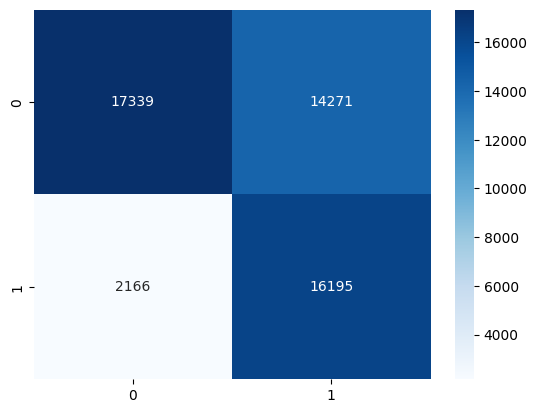

In [15]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

##### 5.1.3. Análises da Matriz de Confusão
---

In [16]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [17]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o diagnóstico negativo. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o diagnóstico negativo. Há {fn} pacientes em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o diagnóstico positivo. Há {tp} pacientes em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o diagnóstico positivo. Há {fp} pacientes em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o diagnóstico negativo. Há 17339 casos que o modelo apontou como resultado negativo, corretamente. Representa 34.70% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o diagnóstico negativo. Há 2166 pacientes em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 4.33% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o diagnóstico positivo. Há 16195 pacientes em que o modelo apontou como resultado positivo, corretamente. Representa 32.41% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o diagnóstico positivo. Há 14271 pacientes em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 28.56% do total de predi

#### 5.2. Pontuação do Modelo (Acurácia Geral)
---

A `Acurácia Geral` tem como foco apontar quantas predições foram assertivas no total. Pode ser uma métrica errônea em conjuntos de dados desbalanceados. Em situações como essa, o modelo pode investir nos casos mais óbvios e deixando a resposta "pré-programada", como um chute, deixando uma acurácia alta e uma eficiência baixa. Dessa forma, esta métrica deve se analisada sempre em conjunto com as demais para garantir o sucesso do modelo.

<div style="text-align: center;">
  <img src="../../imagens/formula_accuracy.png" width="400">
</div>

##### 5.2.1. Criação e visualização da Pontuação do Modelo
---

In [18]:
acuracia = modelo.score(X_teste, y_teste)

In [19]:
print(f'A Acurácia Geral do modelo é de {pm.calcular_percentual(acuracia, 1)}%.')

A Acurácia Geral do modelo é de 67.10692201476857%.


#### 5.3. Relatório de Classificação
---

O `Relatório de Classificação` apresenta métricas de desempenho que mostram o quanto o modelo acerta, utilizando as noções da `Matriz de Confusão` como TN, FN, TP, FP.

1. Precision (Precisão): tem como foco evitar Alarmes Falsos (Falsos Positivos). Uma precisão alta significa que o modelo é cauteloso ao rotular algo como positivo

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

###### 5.3.1. Criação e visualização do Relatório de Classificação
---

In [20]:
relatorio_classificacao = classification_report(y_teste, y_predicao_binaria)

In [21]:
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.89      0.55      0.68     31610
         1.0       0.53      0.88      0.66     18361

    accuracy                           0.67     49971
   macro avg       0.71      0.72      0.67     49971
weighted avg       0.76      0.67      0.67     49971



###### 5.3.2. Extração dos dados do Relatório de Classificação
---

Para a extração dos dados do Relatório de Classificação, deve-se transformar suas saídas em dicionários, à partir do parâmetro `output_dict`.  

In [28]:
dict_relatorio_classificacao = classification_report(y_teste, y_predicao_binaria, output_dict=True)

In [34]:
print(dict_relatorio_classificacao.keys())

dict_keys(['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg'])


In [35]:
precision_0 = dict_relatorio_classificacao['0.0']['precision']
precision_1 = dict_relatorio_classificacao['1.0']['precision']

recall_0 = dict_relatorio_classificacao['0.0']['recall']
recall_1 = dict_relatorio_classificacao['1.0']['recall']

f1_score_0 = dict_relatorio_classificacao['0.0']['f1-score']
f1_score_1 = dict_relatorio_classificacao['1.0']['f1-score']

support_0 = dict_relatorio_classificacao['0.0']['support']
support_1 = dict_relatorio_classificacao['1.0']['support']
support = support_0 + support_1

macro_avg_precision = dict_relatorio_classificacao['macro avg']['precision']
weighted_avg_precision = dict_relatorio_classificacao['weighted avg']['precision']

macro_avg_recall = dict_relatorio_classificacao['macro avg']['recall']
weighted_avg_recall = dict_relatorio_classificacao['weighted avg']['recall']

macro_avg_f1 = dict_relatorio_classificacao['macro avg']['f1-score']
weighted_avg_f1 = dict_relatorio_classificacao['weighted avg']['f1-score']

###### 5.3.3. Análise do Relatório de Classificação a partir de seus dados
---

In [36]:
print('Análises do Relatório de Classificação:')
print('\nCasos onde não foram detectadas ameaças:')
print(f'\n - O total de casos é de {support_0}:')
print(f'\n - Precision é igual a {precision_0} ou {pm.calcular_percentual(precision_0, support_0)}%. Isto corresponde a {(support_0 * precision_0)} predições de testes.')
print(f'\n - Recall é igual a {recall_0} ou {pm.calcular_percentual(recall_0, support_0)}%. Isto corresponde a {(support_0 * recall_0)} predições de testes.')
print(f'\n - F1-Score é igual a {f1_score_0} ou {pm.calcular_percentual(f1_score_0, support_0)}%. Isto corresponde a {(support_0 * f1_score_0)} predições de testes.')

print('\n\nCasos onde foram detectadas ameaças:')
print(f'\n - O total de casos é de {support_1}:')
print(f'\n - Precision é igual a {precision_1} ou {pm.calcular_percentual(precision_1, support_1)}%. Isto corresponde a {(support_1 * precision_1)} predições de testes.')
print(f'\n - Recall é igual a {recall_1} ou {pm.calcular_percentual(recall_1, support_1)}%. Isto corresponde a {(support_1 * recall_1)} predições de testes.')
print(f'\n - F1-Score é igual a {f1_score_1} ou {pm.calcular_percentual(f1_score_1, support_1)}%. Isto corresponde a {(support_1 * f1_score_1)} predições de testes.')

print('\n\nAs médias foram:')
print('\n Média Aritmética (Macro AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: {macro_avg_precision} ou {pm.calcular_percentual(macro_avg_precision, 1)}%. Isto corresponde a {(support * macro_avg_precision)}.')
print(f'\n - Recall: {macro_avg_recall} ou {pm.calcular_percentual(macro_avg_recall, 1)}%. Isto corresponde a {(support * macro_avg_recall)}.')
print(f'\n - F1-Score: {macro_avg_f1} ou {pm.calcular_percentual(macro_avg_f1, 1)}%. Isto corresponde a {(support * macro_avg_f1)}.')

print('\n\n Média Ponderada (Weighted AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: {weighted_avg_precision} ou {pm.calcular_percentual(weighted_avg_precision, 1)}%. Isto corresponde a {(support * weighted_avg_precision)}.')
print(f'\n - Recall: {weighted_avg_recall} ou {pm.calcular_percentual(weighted_avg_recall, 1)}%. Isto corresponde a {(support * weighted_avg_recall)}.')
print(f'\n - F1-Score: {weighted_avg_f1} ou {pm.calcular_percentual(weighted_avg_f1, 1)}%. Isto corresponde a {(support * weighted_avg_f1)}.')

Análises do Relatório de Classificação:

Casos onde não foram detectadas ameaças:

 - O total de casos é de 31610.0:

 - Precision é igual a 0.8889515508843886 ou 0.002812247867397623%. Isto corresponde a 28099.758523455523 predições de testes.

 - Recall é igual a 0.5485289465359063 ou 0.0017353019504457651%. Isto corresponde a 17339.0 predições de testes.

 - F1-Score é igual a 0.6784309889464932 ou 0.0021462543149208895%. Isto corresponde a 21445.20356059865 predições de testes.


Casos onde foram detectadas ameaças:

 - O total de casos é de 18361.0:

 - Precision é igual a 0.5315761832862863 ou 0.0028951374287145924%. Isto corresponde a 9760.270301319502 predições de testes.

 - Recall é igual a 0.8820325690321877 ou 0.004803837312957833%. Isto corresponde a 16195.0 predições de testes.

 - F1-Score é igual a 0.6633624838716284 ou 0.0036128886437101927%. Isto corresponde a 12179.99856636697 predições de testes.


As médias foram:

 Média Aritmética (Macro AVG):

 - O total de caso

#### 5.4. Curva ROC AUC
---

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

##### 5.4.1. Plot do gráfico da Curva ROC AUC
---

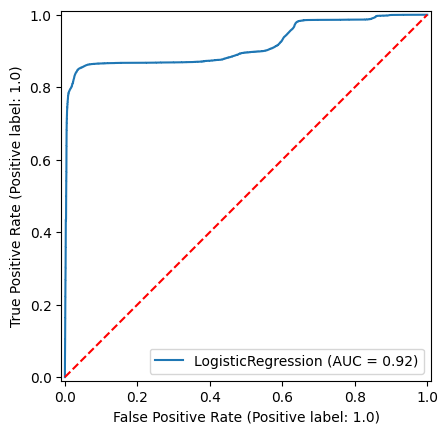

In [31]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 5.4.2. Extração do valor de AUC
---

In [32]:
auc_valor = curva.roc_auc
print(f'O valor de AUC do modelo é {auc_valor}.')

O valor de AUC do modelo é 0.9162549394915889.


##### 5.4.3. Análise do gráfico
---

O gráfico da `Curva ROC AUC` apresenta a curva muito acima da linha tracejada, estando a maior parte junto ao eixo y. Além disso, a métrica `AUC` é de, aproximadamente, 0.92. Isto mostra que o modelo tem um bom potencial de  determinar probabilidades de ataque. Enquanto a `Matriz de Confusão`, `Pontuação` e `Relatório de Classificação` apontam o modelo com dificuldades de desempenho para se chegar à classe `0` e `1`, a `Curva ROC AUC` indica a possibilidade de o modelo pode estar melhor para respostas probabilísticas sobre a possibilidade de ataque ou não. 